# Trabajo Práctico 1 - Algoritmos de Regresión sobre Datasets Públicos

**Minería de Datos 2 - 2026**

Este notebook contiene dos ejercicios prácticos de regresión:

- **Ejercicio 1:** Predicción de demanda de bicicletas compartidas
- **Ejercicio 2:** Predicción de potencia eléctrica de una planta de ciclo combinado

In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import warnings
warnings.filterwarnings('ignore')

---
# Ejercicio 1: Predicción de demanda de bicicletas compartidas

## Descripción del problema

Los sistemas de bicicletas compartidas registran automáticamente el proceso de alquiler y devolución de bicicletas en distintas estaciones de una ciudad. El objetivo es predecir la **cantidad total de alquileres diarios** (variable `cnt`) a partir de información temporal y meteorológica.

### Dataset: Bike Sharing Dataset
- **Fuente:** UCI Machine Learning Repository (Fanaee-T, H. y Gama, J., 2013)
- **Registros:** 731 registros diarios (`day.csv`)
- **Variable objetivo:** `cnt` (usuarios casuales + usuarios registrados)
- **Variables predictoras:** season, yr, mnth, holiday, weekday, workingday, weathersit, temp, atemp, hum, windspeed

## 1. Descarga y carga del dataset

In [57]:
import requests
import zipfile
import io

# Descargar el dataset directamente desde la fuente
url = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
response = requests.get(url)

# Verificar que la descarga fue exitosa
if response.status_code == 200:
    # Extraer el contenido del archivo zip
    with zipfile.ZipFile(io.BytesIO(response.content)) as z:
        # Asumiendo que day.csv está en la carpeta 'day'
        # En este caso, la estructura es bike_sharing_dataset/day.csv
        z.extract('day.csv') # Extrae solo el archivo day.csv
    print("Dataset 'day.csv' descargado y extraído exitosamente.")

    # Cargar el dataset
    df_bike = pd.read_csv('day.csv')
    display(df_bike.head())
else:
    print(f"Error al descargar el dataset: {response.status_code}")
    df_bike = None # Asegúrate de que df_bike sea None si la descarga falla

Dataset 'day.csv' descargado y extraído exitosamente.


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


## 2. Análisis exploratorio de datos (EDA)

In [58]:
# Información general del dataset
print("Forma del dataset:", df_bike.shape)
print("\nTipos de datos:")
print(df_bike.dtypes)
print("\nValores faltantes:")
print(df_bike.isnull().sum())

Forma del dataset: (731, 16)

Tipos de datos:
instant         int64
dteday         object
season          int64
yr              int64
mnth            int64
holiday         int64
weekday         int64
workingday      int64
weathersit      int64
temp          float64
atemp         float64
hum           float64
windspeed     float64
casual          int64
registered      int64
cnt             int64
dtype: object

Valores faltantes:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


In [59]:
# Estadísticas descriptivas
df_bike.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


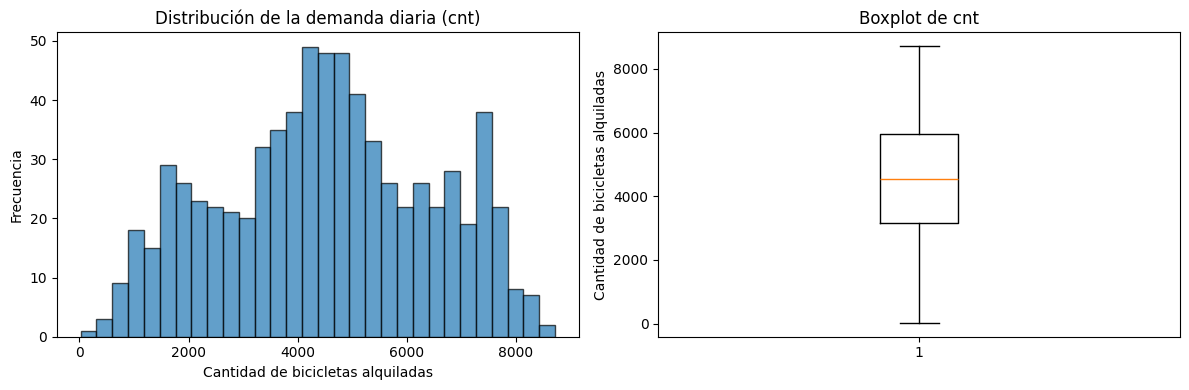

In [60]:
# Distribución de la variable objetivo (cnt)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_bike['cnt'], bins=30, edgecolor='black', alpha=0.7)
axes[0].set_title('Distribución de la demanda diaria (cnt)')
axes[0].set_xlabel('Cantidad de bicicletas alquiladas')
axes[0].set_ylabel('Frecuencia')

axes[1].boxplot(df_bike['cnt'])
axes[1].set_title('Boxplot de cnt')
axes[1].set_ylabel('Cantidad de bicicletas alquiladas')

plt.tight_layout()
plt.show()

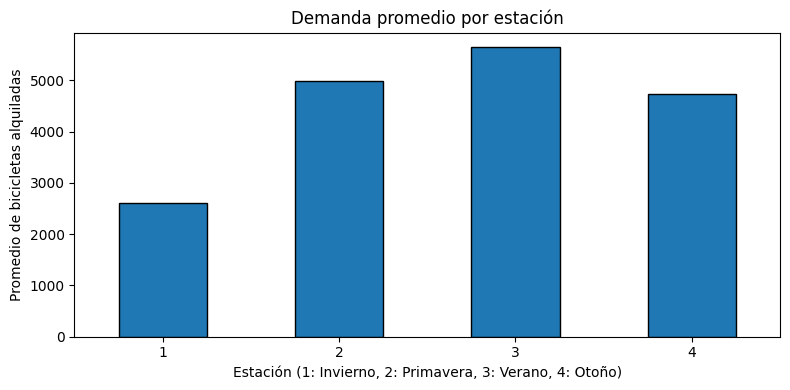

In [61]:
# Distribución por estación del año
plt.figure(figsize=(8, 4))
df_bike.groupby('season')['cnt'].mean().plot(kind='bar', edgecolor='black')
plt.title('Demanda promedio por estación')
plt.xlabel('Estación (1: Invierno, 2: Primavera, 3: Verano, 4: Otoño)')
plt.ylabel('Promedio de bicicletas alquiladas')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

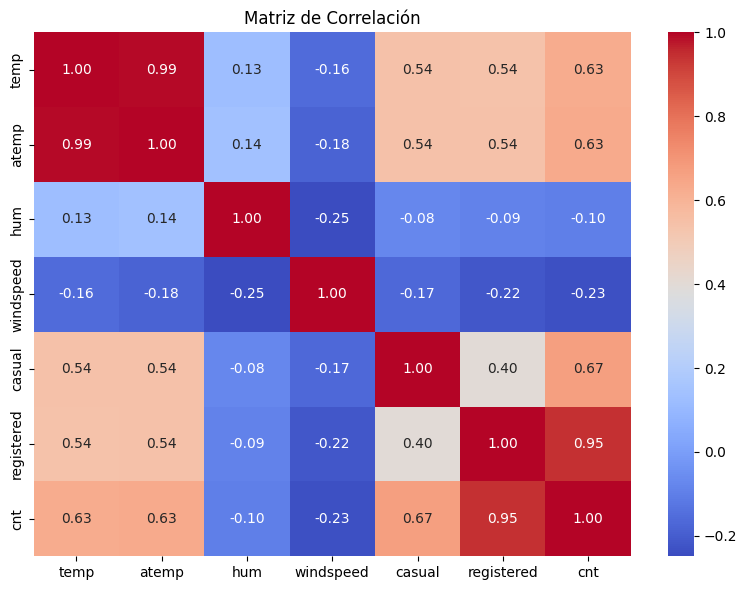

In [62]:
# Matriz de correlación de las variables numéricas
cols_numericas = ['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']
plt.figure(figsize=(8, 6))
sns.heatmap(df_bike[cols_numericas].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlación')
plt.tight_layout()
plt.show()

## 3. Preprocesamiento de datos

In [63]:
# Seleccionar variables predictoras y objetivo
# Excluimos 'instant', 'dteday', 'casual', 'registered' (casual+registered = cnt)
features = ['season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday',
            'weathersit', 'temp', 'atemp', 'hum', 'windspeed']
target = 'cnt'

X = df_bike[features]
y = df_bike[target]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (731, 11)
Target shape: (731,)


In [64]:
# División en conjuntos de entrenamiento y prueba (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Conjunto de entrenamiento: {X_train.shape[0]} registros")
print(f"Conjunto de prueba: {X_test.shape[0]} registros")

Conjunto de entrenamiento: 584 registros
Conjunto de prueba: 147 registros


In [65]:
# Escalado de variables (necesario para Regresión Lineal)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 4. Entrenamiento de modelos

In [66]:
# Función para evaluar modelos
def evaluar_modelo(nombre, modelo, X_test, y_test):
    y_pred = modelo.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    print(f"\n--- {nombre} ---")
    print(f"MSE:  {mse:.2f}")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE:  {mae:.2f}")
    print(f"R²:   {r2:.4f}")

    return {'Modelo': nombre, 'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

In [67]:
# Modelo 1: Regresión Lineal Múltiple
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
resultados_bike = []
resultados_bike.append(evaluar_modelo('Regresión Lineal', lr_model, X_test_scaled, y_test))


--- Regresión Lineal ---
MSE:  691035.01
RMSE: 831.29
MAE:  617.39
R²:   0.8277


In [68]:
# Modelo 2: Random Forest Regressor
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
resultados_bike.append(evaluar_modelo('Random Forest', rf_model, X_test, y_test))


--- Random Forest ---
MSE:  467735.47
RMSE: 683.91
MAE:  435.40
R²:   0.8834


## 5. Comparación de modelos

In [69]:
# Tabla comparativa
df_resultados_bike = pd.DataFrame(resultados_bike)
print("\n=== Comparación de modelos - Ejercicio 1 (Bicicletas) ===")
print(df_resultados_bike.to_string(index=False))


=== Comparación de modelos - Ejercicio 1 (Bicicletas) ===
          Modelo           MSE       RMSE        MAE       R2
Regresión Lineal 691035.008202 831.285155 617.393066 0.827667
   Random Forest 467735.465529 683.911884 435.398636 0.883354


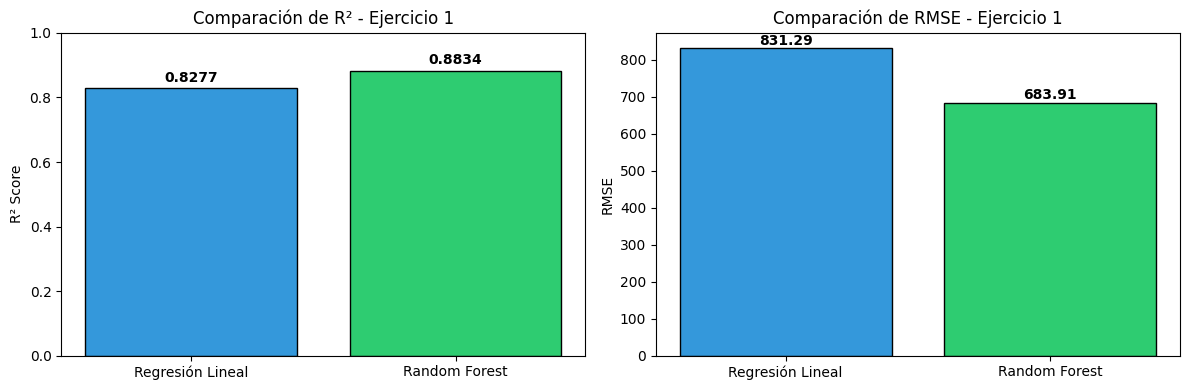

In [70]:
# Gráfico comparativo de R²
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Comparación de R²
modelos = df_resultados_bike['Modelo']
r2_scores = df_resultados_bike['R2']
colors = ['#3498db', '#2ecc71']

axes[0].bar(modelos, r2_scores, color=colors, edgecolor='black')
axes[0].set_title('Comparación de R² - Ejercicio 1')
axes[0].set_ylabel('R² Score')
axes[0].set_ylim(0, 1)
for i, v in enumerate(r2_scores):
    axes[0].text(i, v + 0.02, f'{v:.4f}', ha='center', fontweight='bold')

# Comparación de RMSE
rmse_scores = df_resultados_bike['RMSE']
axes[1].bar(modelos, rmse_scores, color=colors, edgecolor='black')
axes[1].set_title('Comparación de RMSE - Ejercicio 1')
axes[1].set_ylabel('RMSE')
for i, v in enumerate(rmse_scores):
    axes[1].text(i, v + 10, f'{v:.2f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

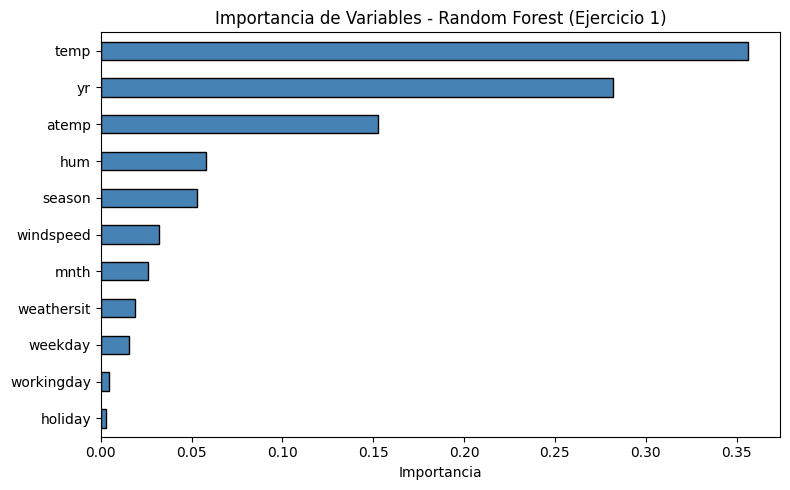

In [71]:
# Importancia de variables (Random Forest)
importancias = pd.Series(rf_model.feature_importances_, index=features)
importancias = importancias.sort_values(ascending=True)

plt.figure(figsize=(8, 5))
importancias.plot(kind='barh', color='steelblue', edgecolor='black')
plt.title('Importancia de Variables - Random Forest (Ejercicio 1)')
plt.xlabel('Importancia')
plt.tight_layout()
plt.show()

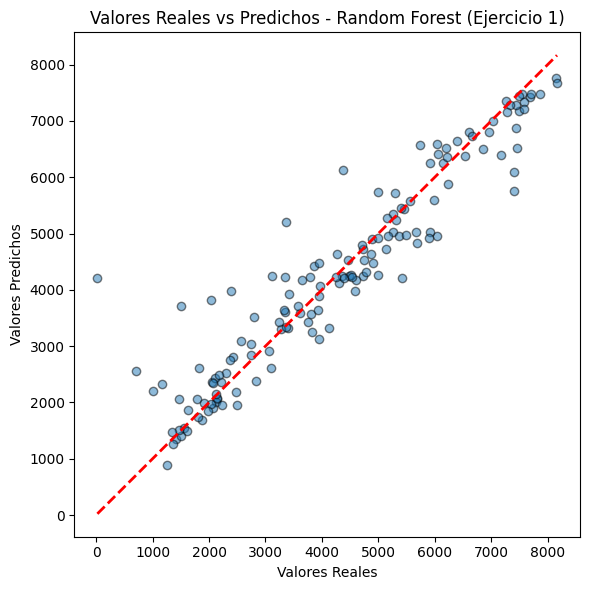

In [72]:
# Gráfico de valores reales vs predichos
y_pred_rf = rf_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.5, edgecolors='black')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Valores Reales')
plt.ylabel('Valores Predichos')
plt.title('Valores Reales vs Predichos - Random Forest (Ejercicio 1)')
plt.tight_layout()
plt.show()

## 6. Conclusiones - Ejercicio 1

- El modelo **Random Forest** captura mejor las relaciones no lineales entre las variables temporales/climáticas y la demanda de bicicletas.
- La **Regresión Lineal** ofrece un baseline interpretable pero con menor capacidad predictiva.
- Las variables de **temperatura** y **año** son las más relevantes para predecir la demanda.

---
# Ejercicio 2: Predicción de la potencia eléctrica de una planta de ciclo combinado

## Descripción del problema

Una planta de generación de energía de ciclo combinado produce electricidad cuyo rendimiento varía según las condiciones ambientales. El objetivo es predecir la **potencia eléctrica neta horaria** (variable `PE`, en MW) a partir de cuatro variables ambientales.

### Dataset: Combined Cycle Power Plant Data Set
- **Fuente:** UCI Machine Learning Repository (Tüfekci, P. y Kaya, H.)
- **Registros:** 9.568 registros (promedios horarios)
- **Variable objetivo:** `PE` - Potencia eléctrica neta horaria (MW)
- **Variables predictoras:** AT (temperatura), V (vacío de escape), AP (presión atmosférica), RH (humedad relativa)

## 1. Descarga y carga del dataset

In [73]:
import requests
import zipfile
import io

# Descargar el dataset directamente desde la fuente
url_plant = "https://archive.ics.uci.edu/static/public/294/combined+cycle+power+plant.zip"
response_plant = requests.get(url_plant)

# Verificar que la descarga fue exitosa
if response_plant.status_code == 200:
    # Extraer el contenido del archivo zip
    with zipfile.ZipFile(io.BytesIO(response_plant.content)) as z:
        # El archivo .xlsx está dentro de la carpeta 'CCPP' en el zip
        z.extractall('.') # Extrae todos los contenidos del zip
    print("Dataset 'combined+cycle+power+plant.zip' descargado y extraído exitosamente.")

    # Cargar el dataset
    df_plant = pd.read_excel('CCPP/Folds5x2_pp.xlsx')
    display(df_plant.head())
else:
    print(f"Error al descargar el dataset: {response_plant.status_code}")
    df_plant = None

Dataset 'combined+cycle+power+plant.zip' descargado y extraído exitosamente.


,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


## 2. Análisis exploratorio de datos (EDA)

In [74]:
# Información general del dataset
print("Forma del dataset:", df_plant.shape)
print("\nTipos de datos:")
print(df_plant.dtypes)
print("\nValores faltantes:")
print(df_plant.isnull().sum())

Forma del dataset: (9568, 5)

Tipos de datos:
AT    float64
V     float64
AP    float64
RH    float64
PE    float64
dtype: object

Valores faltantes:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64


In [75]:
# Estadísticas descriptivas
df_plant.describe()

,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


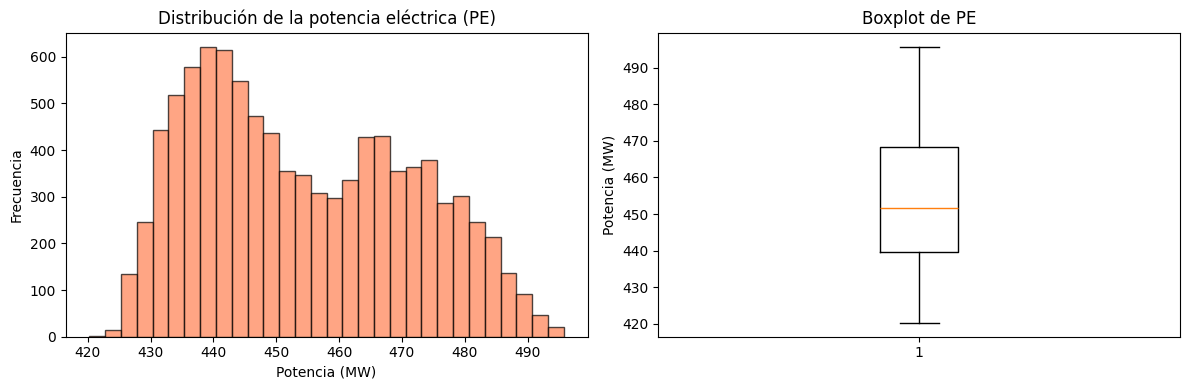

In [76]:
# Distribución de la variable objetivo (PE)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df_plant['PE'], bins=30, edgecolor='black', alpha=0.7, color='coral')
axes[0].set_title('Distribución de la potencia eléctrica (PE)')
axes[0].set_xlabel('Potencia (MW)')
axes[0].set_ylabel('Frecuencia')

axes[1].boxplot(df_plant['PE'])
axes[1].set_title('Boxplot de PE')
axes[1].set_ylabel('Potencia (MW)')

plt.tight_layout()
plt.show()

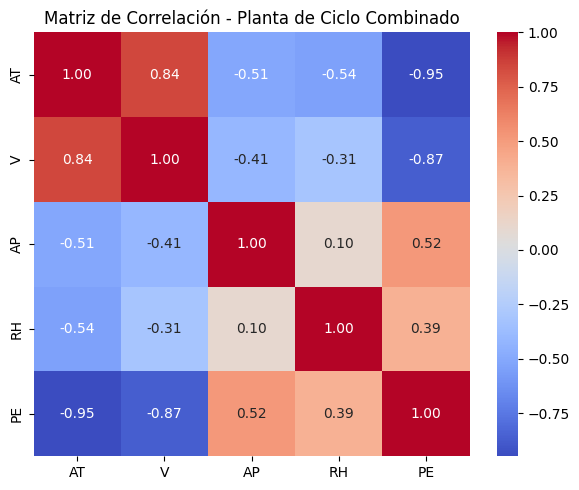

In [77]:
# Matriz de correlación
plt.figure(figsize=(6, 5))
sns.heatmap(df_plant.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriz de Correlación - Planta de Ciclo Combinado')
plt.tight_layout()
plt.show()

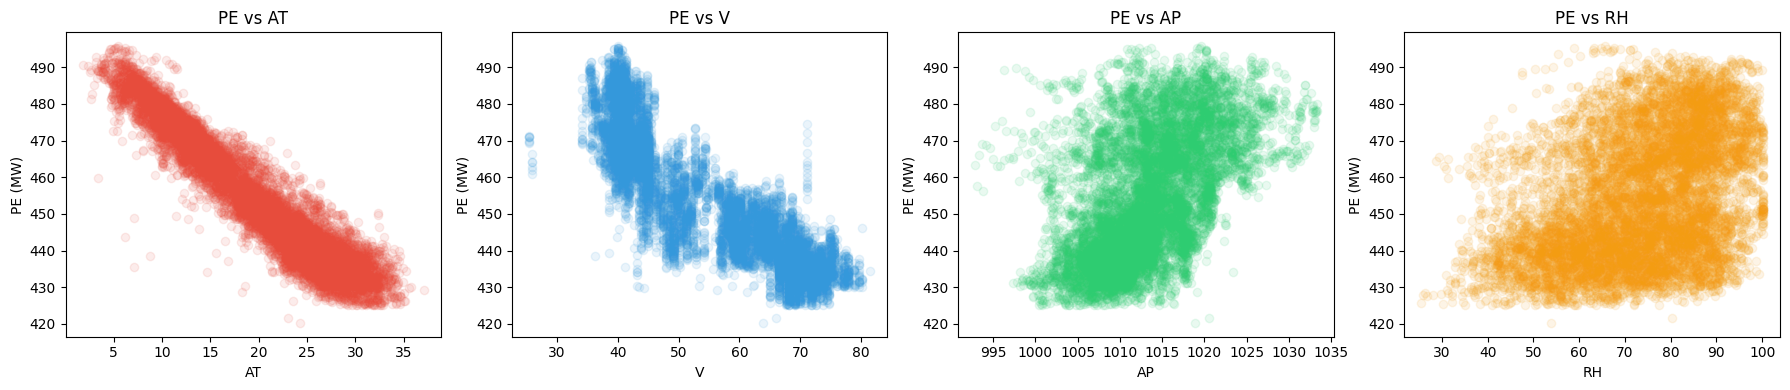

In [78]:
# Scatter plots de cada variable vs PE
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
variables = ['AT', 'V', 'AP', 'RH']
colores = ['#e74c3c', '#3498db', '#2ecc71', '#f39c12']

for i, var in enumerate(variables):
    axes[i].scatter(df_plant[var], df_plant['PE'], alpha=0.1, color=colores[i])
    axes[i].set_xlabel(var)
    axes[i].set_ylabel('PE (MW)')
    axes[i].set_title(f'PE vs {var}')

plt.tight_layout()
plt.show()

## 3. Preprocesamiento de datos

In [79]:
# Variables predictoras y objetivo
features_plant = ['AT', 'V', 'AP', 'RH']
target_plant = 'PE'

X2 = df_plant[features_plant]
y2 = df_plant[target_plant]

print("Features shape:", X2.shape)
print("Target shape:", y2.shape)

Features shape: (9568, 4)
Target shape: (9568,)


In [80]:
# División en conjuntos de entrenamiento y prueba (80/20)
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

print(f"Conjunto de entrenamiento: {X2_train.shape[0]} registros")
print(f"Conjunto de prueba: {X2_test.shape[0]} registros")

Conjunto de entrenamiento: 7654 registros
Conjunto de prueba: 1914 registros


In [81]:
# Escalado de variables
scaler2 = StandardScaler()
X2_train_scaled = scaler2.fit_transform(X2_train)
X2_test_scaled = scaler2.transform(X2_test)

## 4. Entrenamiento de modelos

In [82]:
resultados_plant = []

In [83]:
# Modelo 1: Regresión Lineal Múltiple
lr_model2 = LinearRegression()
lr_model2.fit(X2_train_scaled, y2_train)
resultados_plant.append(evaluar_modelo('Regresión Lineal', lr_model2, X2_test_scaled, y2_test))


--- Regresión Lineal ---
MSE:  20.27
RMSE: 4.50
MAE:  3.60
R²:   0.9301


In [84]:
# Modelo 2: Random Forest Regressor
rf_model2 = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)
rf_model2.fit(X2_train, y2_train)
resultados_plant.append(evaluar_modelo('Random Forest', rf_model2, X2_test, y2_test))


--- Random Forest ---
MSE:  11.98
RMSE: 3.46
MAE:  2.58
R²:   0.9587


## 5. Comparación de modelos

In [85]:
# Tabla comparativa
df_resultados_plant = pd.DataFrame(resultados_plant)
print("\n=== Comparación de modelos - Ejercicio 2 (Planta de Ciclo Combinado) ===")
print(df_resultados_plant.to_string(index=False))


=== Comparación de modelos - Ejercicio 2 (Planta de Ciclo Combinado) ===
          Modelo       MSE     RMSE      MAE       R2
Regresión Lineal 20.273706 4.502633 3.595913 0.930105
   Random Forest 11.978119 3.460942 2.575267 0.958704


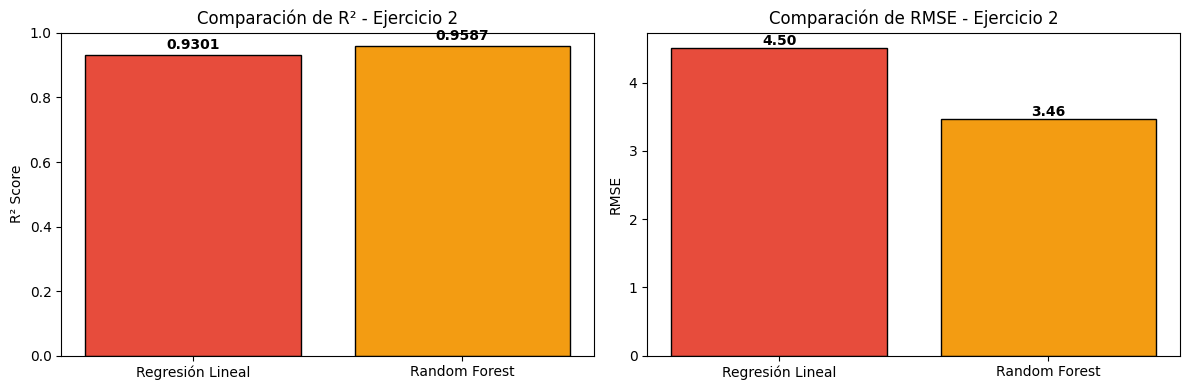

In [86]:
# Gráfico comparativo de R²
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

modelos2 = df_resultados_plant['Modelo']
r2_scores2 = df_resultados_plant['R2']
colors = ['#e74c3c', '#f39c12']

axes[0].bar(modelos2, r2_scores2, color=colors, edgecolor='black')
axes[0].set_title('Comparación de R² - Ejercicio 2')
axes[0].set_ylabel('R² Score')
axes[0].set_ylim(0, 1)
for i, v in enumerate(r2_scores2):
    axes[0].text(i, v + 0.02, f'{v:.4f}', ha='center', fontweight='bold')

rmse_scores2 = df_resultados_plant['RMSE']
axes[1].bar(modelos2, rmse_scores2, color=colors, edgecolor='black')
axes[1].set_title('Comparación de RMSE - Ejercicio 2')
axes[1].set_ylabel('RMSE')
for i, v in enumerate(rmse_scores2):
    axes[1].text(i, v + 0.05, f'{v:.2f}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

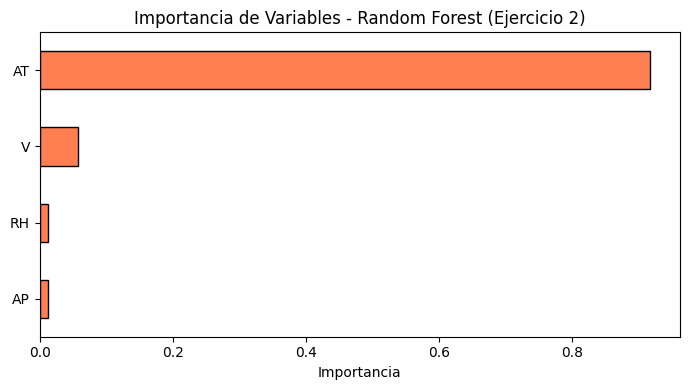

In [87]:
# Importancia de variables (Random Forest)
importancias2 = pd.Series(rf_model2.feature_importances_, index=features_plant)
importancias2 = importancias2.sort_values(ascending=True)

plt.figure(figsize=(7, 4))
importancias2.plot(kind='barh', color='coral', edgecolor='black')
plt.title('Importancia de Variables - Random Forest (Ejercicio 2)')
plt.xlabel('Importancia')
plt.tight_layout()
plt.show()

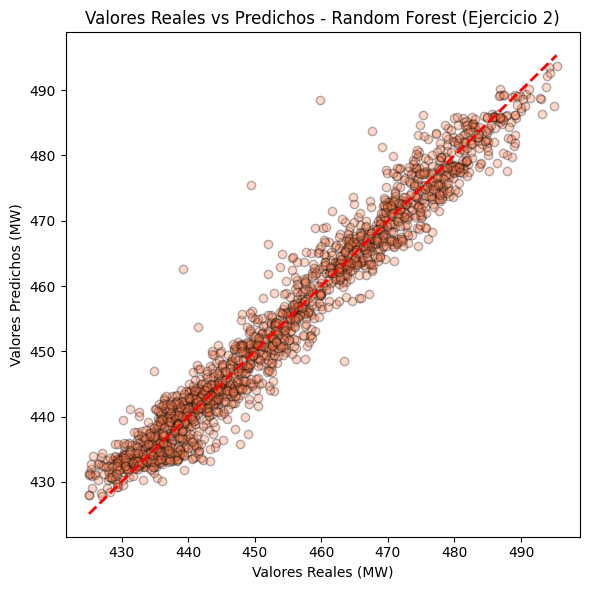

In [88]:
# Gráfico de valores reales vs predichos
y2_pred_rf = rf_model2.predict(X2_test)

plt.figure(figsize=(6, 6))
plt.scatter(y2_test, y2_pred_rf, alpha=0.3, edgecolors='black', color='coral')
plt.plot([y2_test.min(), y2_test.max()], [y2_test.min(), y2_test.max()], 'r--', lw=2)
plt.xlabel('Valores Reales (MW)')
plt.ylabel('Valores Predichos (MW)')
plt.title('Valores Reales vs Predichos - Random Forest (Ejercicio 2)')
plt.tight_layout()
plt.show()

## 6. Conclusiones - Ejercicio 2

- Ambos modelos obtienen muy buenos resultados, ya que las relaciones entre las variables ambientales y la potencia son predominantemente lineales.
- La **temperatura ambiente (AT)** es la variable más influyente en la predicción de la potencia eléctrica.
- El **Random Forest** ofrece una ligera mejora respecto a la Regresión Lineal, y proporciona información adicional sobre la importancia de cada variable.
- El alto valor de R² indica que las cuatro variables ambientales explican gran parte de la variación en la potencia generada.